In [30]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [31]:
import pandas as pd

file_path = r"C:\Users\Asus\OneDrive\Desktop\BlinkIT Grocery Sales Analysis\Dataset\BlinkIT Grocery Data (1).xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [32]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [33]:
df.shape

(8523, 12)

In [34]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [36]:
df.describe(include='all')

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
count,8523,8523,8523,8523.000000,8523,8523,8523,8523,8523.000000,7060.000000,8523.000000,8523.000000
unique,5,1559,16,NaN,10,3,3,4,NaN,NaN,NaN,NaN
top,Low Fat,FDW13,Fruits and Vegetables,NaN,OUT027,Tier 3,Medium,Supermarket Type1,NaN,NaN,NaN,NaN
freq,5089,10,1232,NaN,935,3350,3631,5577,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2016.450546,NaN,NaN,NaN,NaN,0.066132,12.857645,140.992783,3.965857
std,NaN,NaN,NaN,3.189396,NaN,NaN,NaN,NaN,0.051598,4.643456,62.275067,0.605651
min,NaN,NaN,NaN,2011.000000,NaN,NaN,NaN,NaN,0.000000,4.555000,31.290000,1.000000
25%,NaN,NaN,NaN,2014.000000,NaN,NaN,NaN,NaN,0.026989,8.773750,93.826500,4.000000
50%,NaN,NaN,NaN,2016.000000,NaN,NaN,NaN,NaN,0.053931,12.600000,143.012800,4.000000
75%,NaN,NaN,NaN,2018.000000,NaN,NaN,NaN,NaN,0.094585,16.850000,185.643700,4.200000


In [37]:
missing_values = df.isnull().sum()

print(missing_values)

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64


In [38]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

Item Fat Content              0.000000
Item Identifier               0.000000
Item Type                     0.000000
Outlet Establishment Year     0.000000
Outlet Identifier             0.000000
Outlet Location Type          0.000000
Outlet Size                   0.000000
Outlet Type                   0.000000
Item Visibility               0.000000
Item Weight                  17.165317
Sales                         0.000000
Rating                        0.000000
dtype: float64


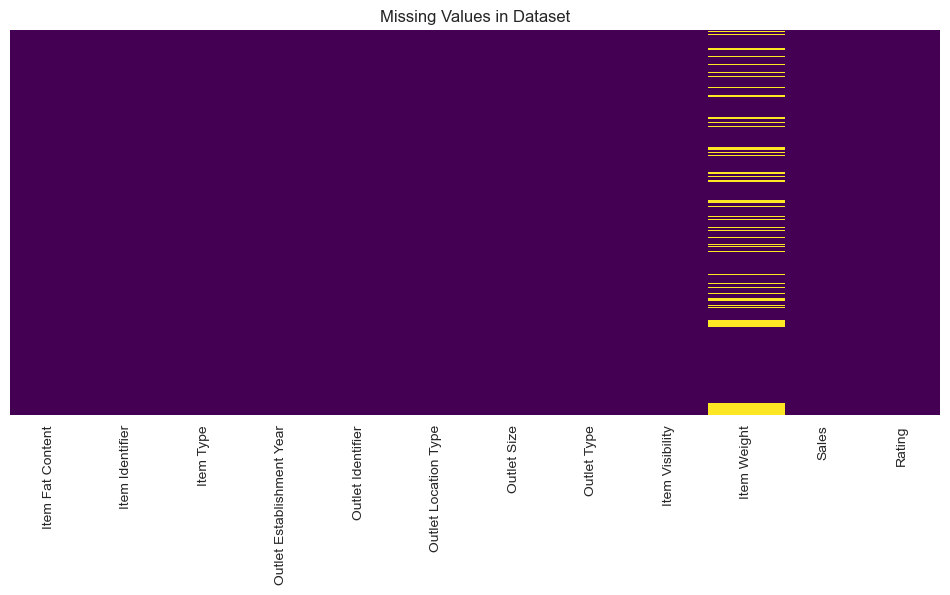

In [39]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values in Dataset")
plt.show()

In [40]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [42]:
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

In [43]:
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

In [44]:
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

In [45]:
print("Missing Item Weight:",
      df['Item Weight'].isnull().sum())

print("Percentage:",
      df['Item Weight'].isnull().mean() * 100)

Missing Item Weight: 1463
Percentage: 17.165317376510618


In [46]:
df['Item Weight'] = df['Item Weight'].fillna(
    df.groupby('Item Identifier')['Item Weight']
    .transform('median')
)

In [47]:
df['Item Weight'] = df['Item Weight'].fillna(
    df['Item Weight'].median()
)

In [48]:
df.isnull().sum()

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64

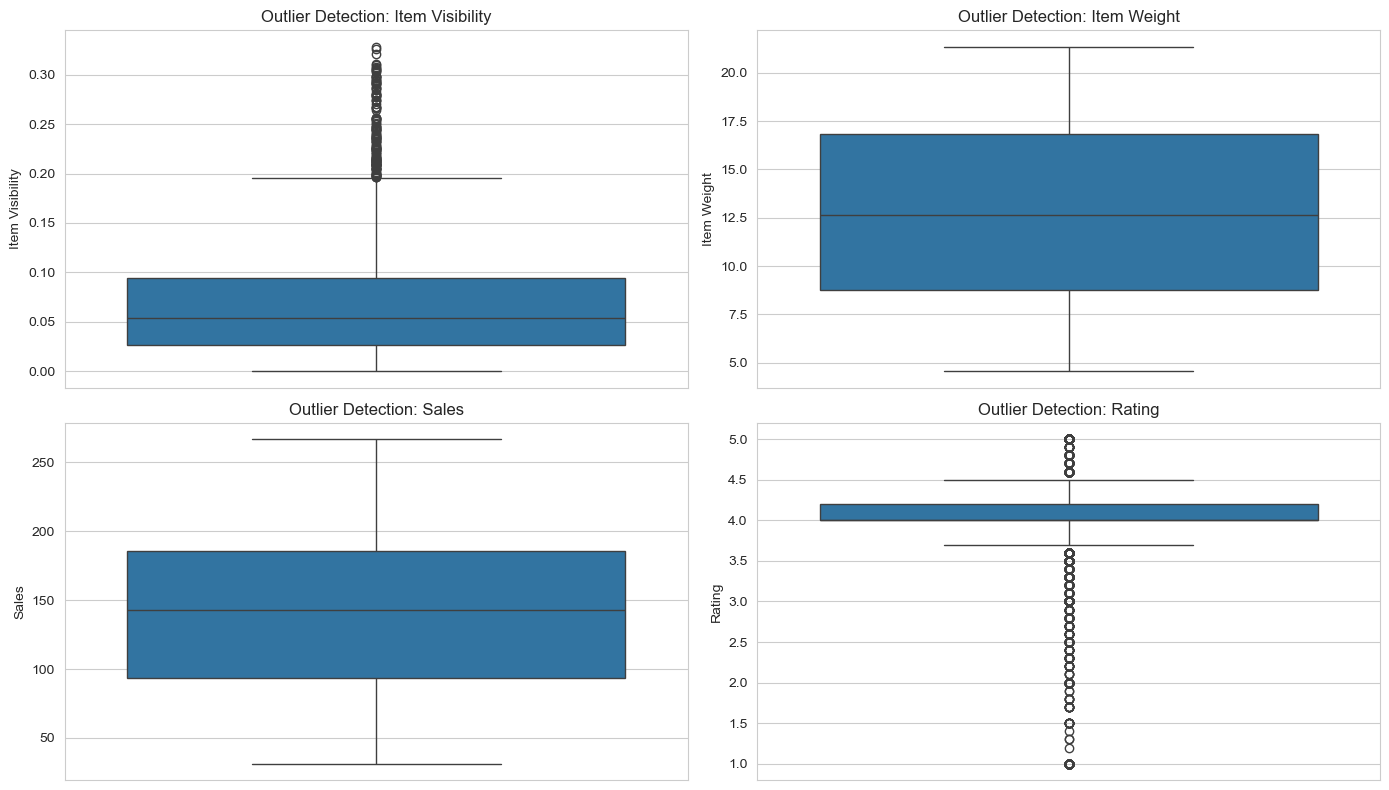

In [49]:
numerical_columns = [
    'Item Visibility',
    'Item Weight',
    'Sales',
    'Rating'
]

plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_columns, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(y=df[col])

    plt.title(f'Outlier Detection: {col}')

plt.tight_layout()
plt.show()

In [50]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Column: Item Visibility
Lower Limit: -0.07440424500000001
Upper Limit: 0.195979015
Number of Outliers: 144

Column: Item Weight
Lower Limit: -3.3125000000000018
Upper Limit: 28.947500000000005
Number of Outliers: 0

Column: Sales
Lower Limit: -43.8993
Upper Limit: 323.3695
Number of Outliers: 0

Column: Rating
Lower Limit: 3.6999999999999997
Upper Limit: 4.5
Number of Outliers: 1931


In [51]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Final Dataset Shape: (8523, 12)

Missing Values:
Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64

Duplicate Records:
0


In [52]:
df.to_csv(
    "Cleaned_BlinkIT_Data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [53]:
total_sales = df['Sales'].sum()

average_sales = df['Sales'].mean()

total_products = df['Item Identifier'].nunique()

total_outlets = df['Outlet Identifier'].nunique()

average_rating = df['Rating'].mean()

average_weight = df['Item Weight'].mean()

print("========== BLINKIT BUSINESS OVERVIEW ==========")

print("Total Sales:", round(total_sales, 2))

print("Average Sales:", round(average_sales, 2))

print("Total Unique Products:", total_products)

print("Total Outlets:", total_outlets)

print("Average Customer Rating:", round(average_rating, 2))

print("Average Item Weight:", round(average_weight, 2))

print("===============================================")

========== BLINKIT BUSINESS OVERVIEW ==========
Total Sales: 1201681.49
Average Sales: 140.99
Total Unique Products: 1559
Total Outlets: 10
Average Customer Rating: 3.97
Average Item Weight: 12.88


# PHASE 3: EXPLORATORY DATA ANALYSIS

## 1. Overall Business Performance Analysis

In this section, we analyze the overall sales performance
of BlinkIT using key business performance indicators.

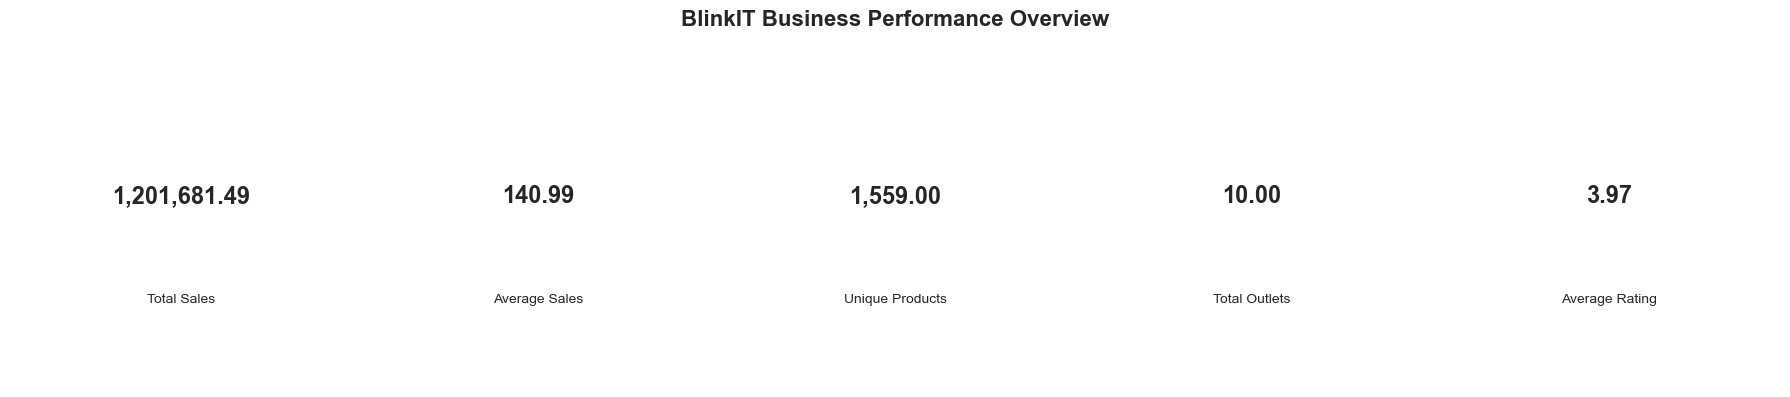

In [54]:
kpis = {
    'Total Sales': total_sales,
    'Average Sales': average_sales,
    'Unique Products': total_products,
    'Total Outlets': total_outlets,
    'Average Rating': average_rating
}

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, (label, value) in zip(axes, kpis.items()):

    ax.text(
        0.5, 0.55,
        f'{value:,.2f}',
        fontsize=17,
        fontweight='bold',
        ha='center'
    )

    ax.text(
        0.5, 0.25,
        label,
        fontsize=10,
        ha='center'
    )

    ax.axis('off')

plt.suptitle(
    'BlinkIT Business Performance Overview',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### Business Performance Insights

1. Total sales represent the overall revenue generated
   across all BlinkIT outlets.

2. Average sales indicate the average revenue generated
   per product-outlet record.

3. The dataset contains multiple unique products and
   outlets, providing a broad view of business performance.

4. Average customer rating helps evaluate the general
   customer perception of products.

5. BlinkIT generated total sales of 1,201,681.49
   across the dataset.

6. The average sales value per product-outlet record
   is 140.99.

7. The dataset covers 1,559 unique products across
   10 different outlets.

8. The average customer rating is 3.97, indicating
   generally positive customer feedback.

## 2. Product Category Analysis

This section analyzes sales performance across
different product categories to identify the
highest and lowest revenue-generating categories.

In [56]:
category_sales = (
    df.groupby('Item Type')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Breads                    35379.1198
Hard Drinks               29334.6806
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


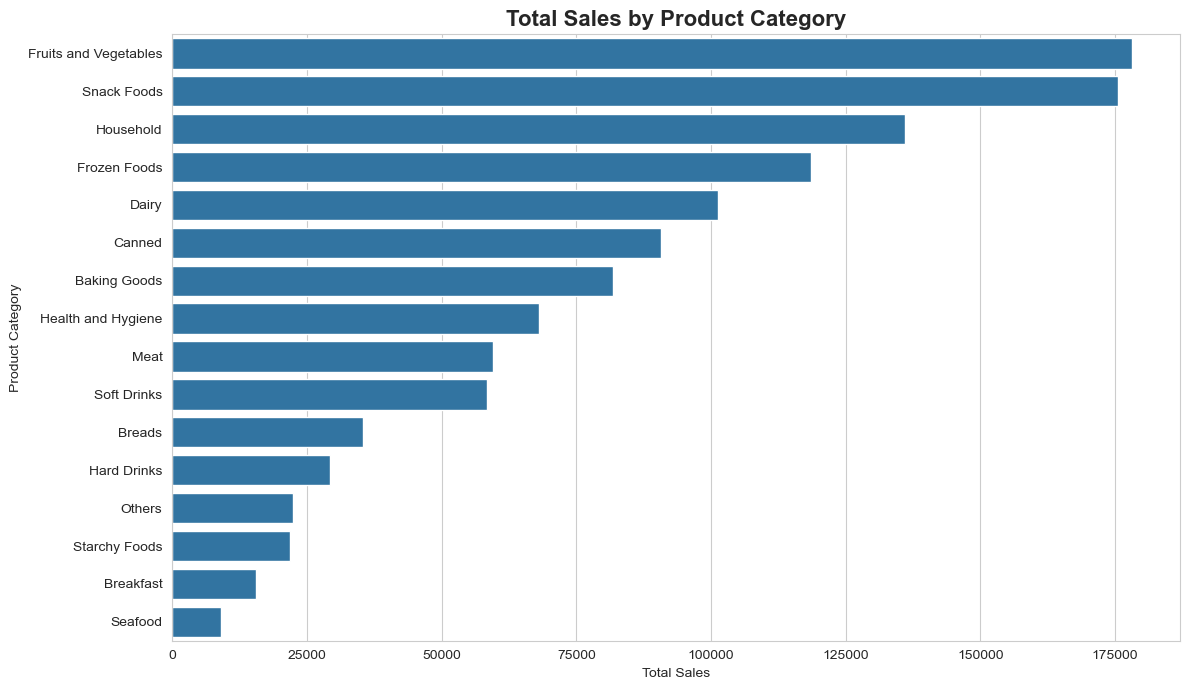

In [57]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title(
    'Total Sales by Product Category',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Total Sales')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [58]:
top_5_categories = category_sales.head(5)

bottom_5_categories = category_sales.tail(5)

print("TOP 5 PRODUCT CATEGORIES")
print(top_5_categories)

print("\nBOTTOM 5 PRODUCT CATEGORIES")
print(bottom_5_categories)

TOP 5 PRODUCT CATEGORIES
Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Name: Sales, dtype: float64

BOTTOM 5 PRODUCT CATEGORIES
Item Type
Hard Drinks      29334.6806
Others           22451.8916
Starchy Foods    21880.0274
Breakfast        15596.6966
Seafood           9077.8700
Name: Sales, dtype: float64


In [59]:
category_percentage = (
    category_sales / total_sales
) * 100

print(
    category_percentage.sort_values(
        ascending=False
    ).round(2)
)

Item Type
Fruits and Vegetables    14.82
Snack Foods              14.60
Household                11.32
Frozen Foods              9.87
Dairy                     8.43
Canned                    7.55
Baking Goods              6.82
Health and Hygiene        5.66
Meat                      4.95
Soft Drinks               4.87
Breads                    2.94
Hard Drinks               2.44
Others                    1.87
Starchy Foods             1.82
Breakfast                 1.30
Seafood                   0.76
Name: Sales, dtype: float64


### Product Category Insights

1. The highest revenue-generating category is Fruits and Vegetables.

2. The lowest revenue-generating category is Seafood.

3. The top-performing categories contribute
   significantly to overall BlinkIT sales.

4. Management should analyze the demand and inventory
   requirements of lower-performing categories.

5. Product assortment and promotional strategies
   should be evaluated based on category performance.

## 3. Outlet Performance Analysis

This section evaluates BlinkIT outlet performance
based on outlet type, size, and location.

The objective is to identify high-performing outlets
and understand factors influencing sales.

In [61]:
outlet_type_sales = (
    df.groupby('Outlet Type')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(outlet_type_sales)

Outlet Type
Supermarket Type1    787549.8928
Grocery Store        151939.1490
Supermarket Type2    131477.7764
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


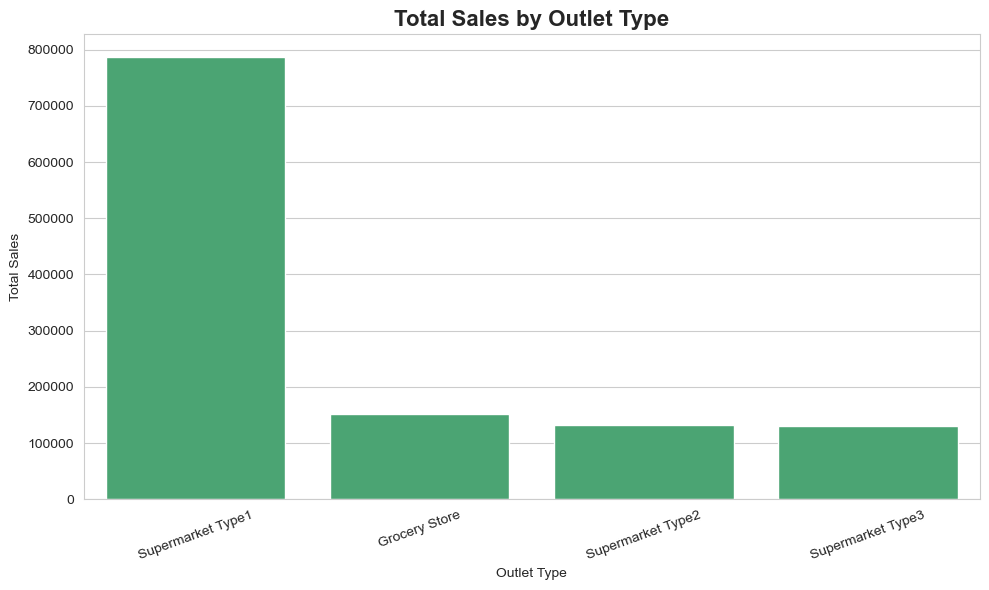

In [62]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=outlet_type_sales.index,
    y=outlet_type_sales.values,
    color='mediumseagreen'
)

plt.title(
    'Total Sales by Outlet Type',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Outlet Type')
plt.ylabel('Total Sales')

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [63]:
size_sales = (
    df.groupby('Outlet Size', dropna=False)['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(size_sales)

Outlet Size
Medium    507895.7364
Small     444794.1704
High      248991.5860
Name: Sales, dtype: float64


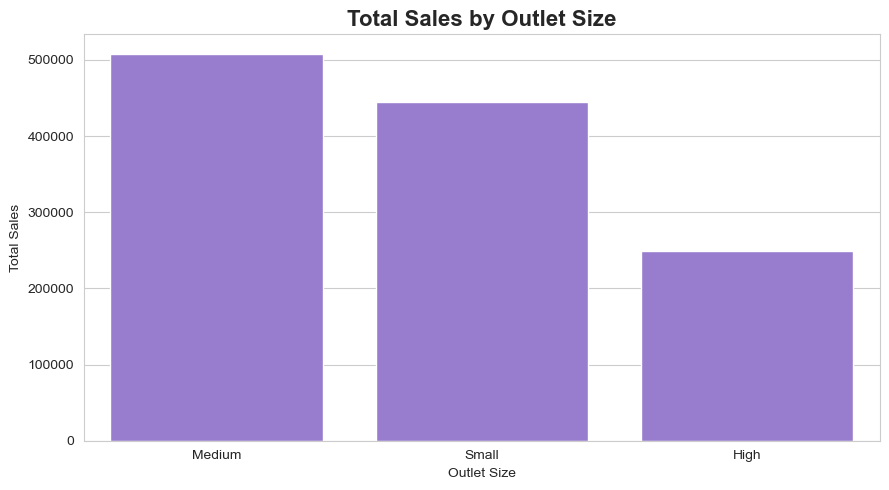

In [64]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=size_sales.index.astype(str),
    y=size_sales.values,
    color='mediumpurple'
)

plt.title(
    'Total Sales by Outlet Size',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Outlet Size')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [65]:
outlet_ranking = (
    df.groupby('Outlet Identifier')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("TOP 5 OUTLETS")
print(outlet_ranking.head(5))

print("\nBOTTOM 5 OUTLETS")
print(outlet_ranking.tail(5))

TOP 5 OUTLETS
Outlet Identifier
OUT035    133103.9070
OUT046    132113.3698
OUT013    131809.0156
OUT018    131477.7764
OUT045    130942.7802
Name: Sales, dtype: float64

BOTTOM 5 OUTLETS
Outlet Identifier
OUT027    130714.6746
OUT049    130476.8598
OUT017    129103.9604
OUT010     78131.5666
OUT019     73807.5824
Name: Sales, dtype: float64


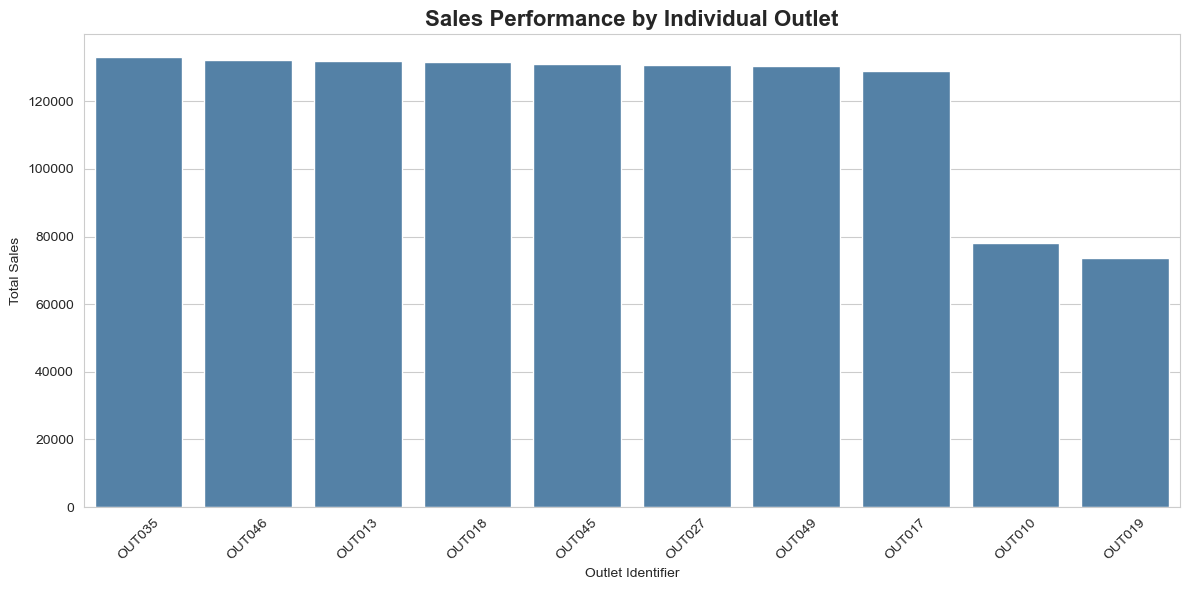

In [66]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=outlet_ranking.index,
    y=outlet_ranking.values,
    color='steelblue'
)

plt.title(
    'Sales Performance by Individual Outlet',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Outlet Identifier')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [67]:
outlet_comparison = (
    df.groupby('Outlet Identifier')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Records=('Sales', 'count')
    )
    .sort_values(by='Total_Sales', ascending=False)
)

print(outlet_comparison.round(2))

                   Total_Sales  Average_Sales  Records
Outlet Identifier                                     
OUT035               133103.91         143.12      930
OUT046               132113.37         142.06      930
OUT013               131809.02         141.43      932
OUT018               131477.78         141.68      928
OUT045               130942.78         140.95      929
OUT027               130714.67         139.80      935
OUT049               130476.86         140.30      930
OUT017               129103.96         139.42      926
OUT010                78131.57         140.78      555
OUT019                73807.58         139.79      528


### Outlet Performance Insights

1. Supermarket Type1 generates the highest total
   revenue among all outlet types.

2. Tier 3 locations contribute the largest share
   of total sales.

3. Outlet size analysis helps identify differences
   in revenue contribution across store sizes.

4. Individual outlet rankings reveal the strongest
   and weakest revenue contributors.

5. Average sales per record provides an additional
   measure for comparing outlets with different
   numbers of records.

### Business Recommendations

1. Investigate the factors contributing to the
   strong total revenue of Supermarket Type1.

2. Examine the performance of Tier 3 outlets
   before making expansion decisions.

3. Review low-revenue outlets to understand
   whether performance differences result from
   product availability, assortment, or other factors.

4. Compare total sales and average sales together
   to avoid misleading outlet rankings.

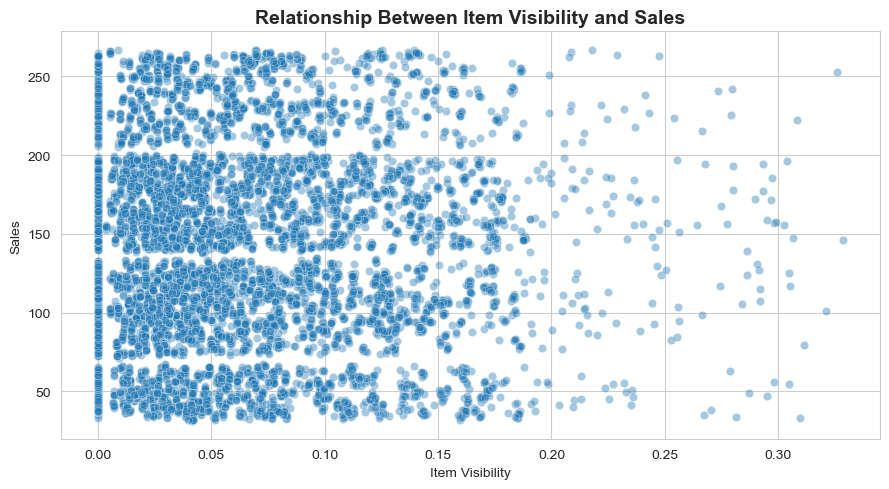

In [68]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Item Visibility',
    y='Sales',
    alpha=0.4
)

plt.title(
    'Relationship Between Item Visibility and Sales',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Item Visibility')
plt.ylabel('Sales')

plt.tight_layout()
plt.show()

In [69]:
visibility_corr = df['Item Visibility'].corr(df['Sales'])

print("Visibility-Sales Correlation:", round(visibility_corr, 3))

Visibility-Sales Correlation: -0.001


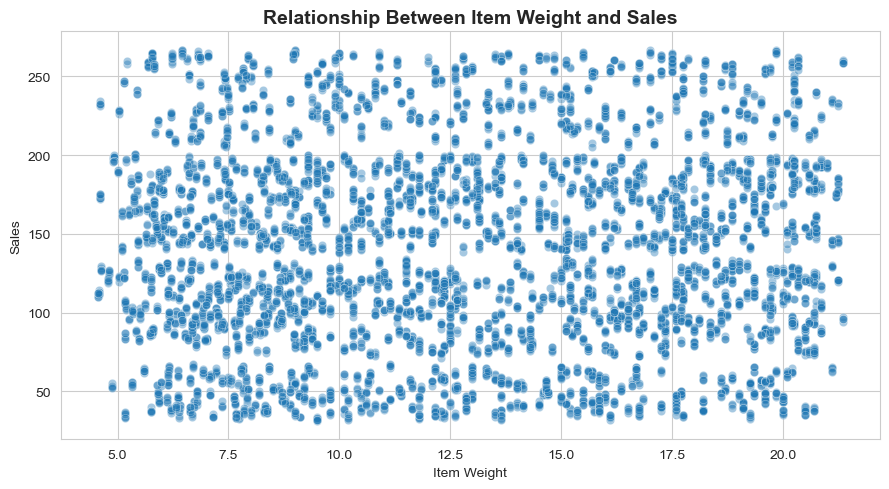

In [70]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Item Weight',
    y='Sales',
    alpha=0.4
)

plt.title(
    'Relationship Between Item Weight and Sales',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Item Weight')
plt.ylabel('Sales')

plt.tight_layout()
plt.show()

In [71]:
weight_corr = df['Item Weight'].corr(df['Sales'])

print("Weight-Sales Correlation:", round(weight_corr, 3))

Weight-Sales Correlation: 0.026


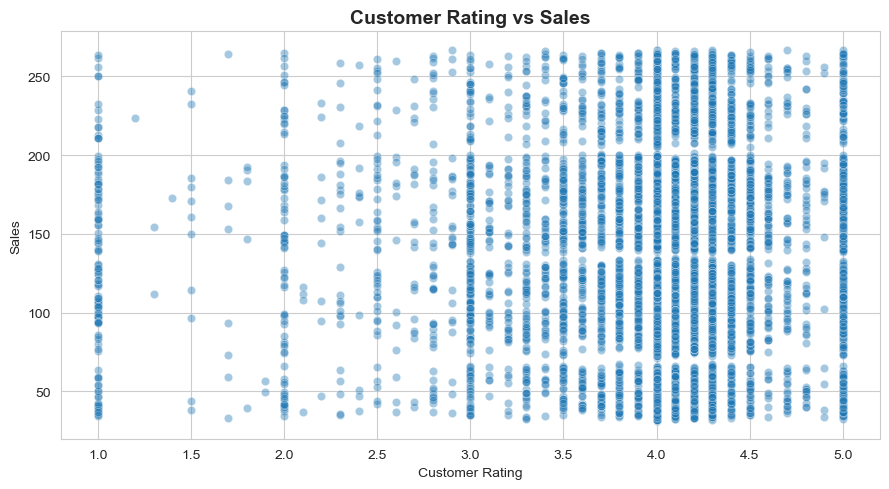

In [72]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Rating',
    y='Sales',
    alpha=0.4
)

plt.title(
    'Customer Rating vs Sales',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Customer Rating')
plt.ylabel('Sales')

plt.tight_layout()
plt.show()

In [73]:
rating_corr = df['Rating'].corr(df['Sales'])

print("Rating-Sales Correlation:", round(rating_corr, 3))

Rating-Sales Correlation: 0.011


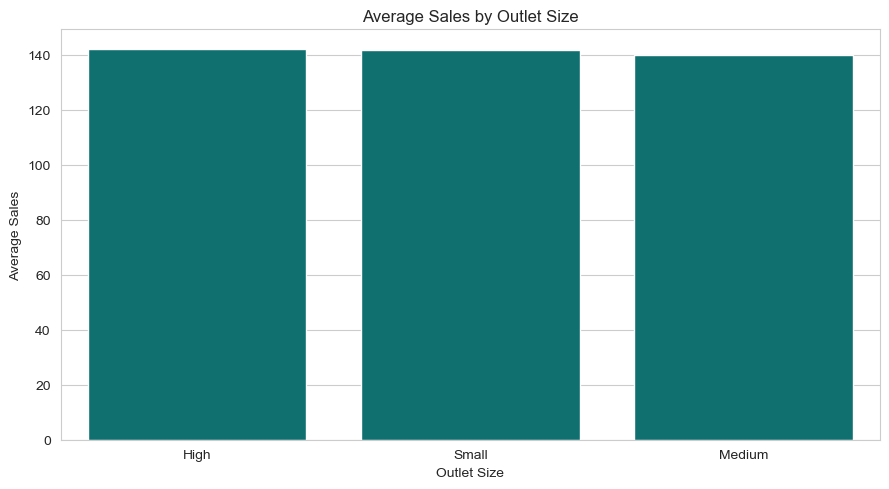

Outlet Size
High      142.037414
Small     141.699322
Medium    139.877647
Name: Sales, dtype: float64


In [74]:
size_avg_sales = (
    df.groupby('Outlet Size', dropna=False)['Sales']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=size_avg_sales.index.astype(str),
    y=size_avg_sales.values,
    color='teal'
)

plt.title('Average Sales by Outlet Size')
plt.xlabel('Outlet Size')
plt.ylabel('Average Sales')

plt.tight_layout()
plt.show()

print(size_avg_sales)

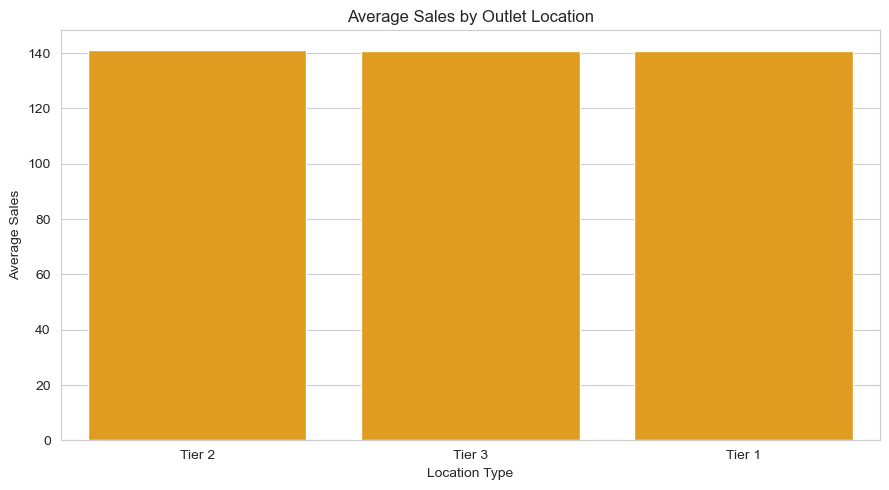

Outlet Location Type
Tier 2    141.167198
Tier 3    140.935234
Tier 1    140.870106
Name: Sales, dtype: float64


In [75]:
location_avg_sales = (
    df.groupby('Outlet Location Type')['Sales']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=location_avg_sales.index,
    y=location_avg_sales.values,
    color='orange'
)

plt.title('Average Sales by Outlet Location')
plt.xlabel('Location Type')
plt.ylabel('Average Sales')

plt.tight_layout()
plt.show()

print(location_avg_sales)

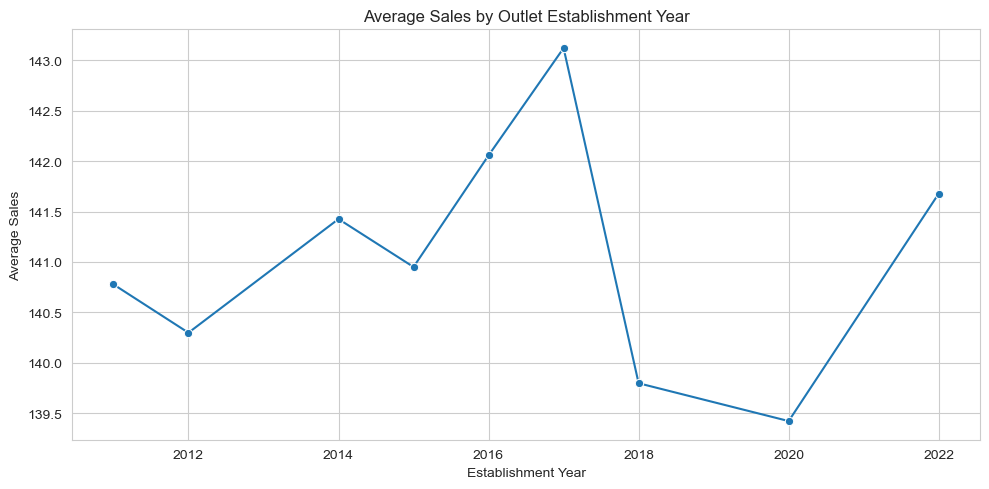

In [76]:
year_sales = (
    df.groupby('Outlet Establishment Year')['Sales']
    .mean()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=year_sales.index,
    y=year_sales.values,
    marker='o'
)

plt.title('Average Sales by Outlet Establishment Year')
plt.xlabel('Establishment Year')
plt.ylabel('Average Sales')

plt.tight_layout()
plt.show()

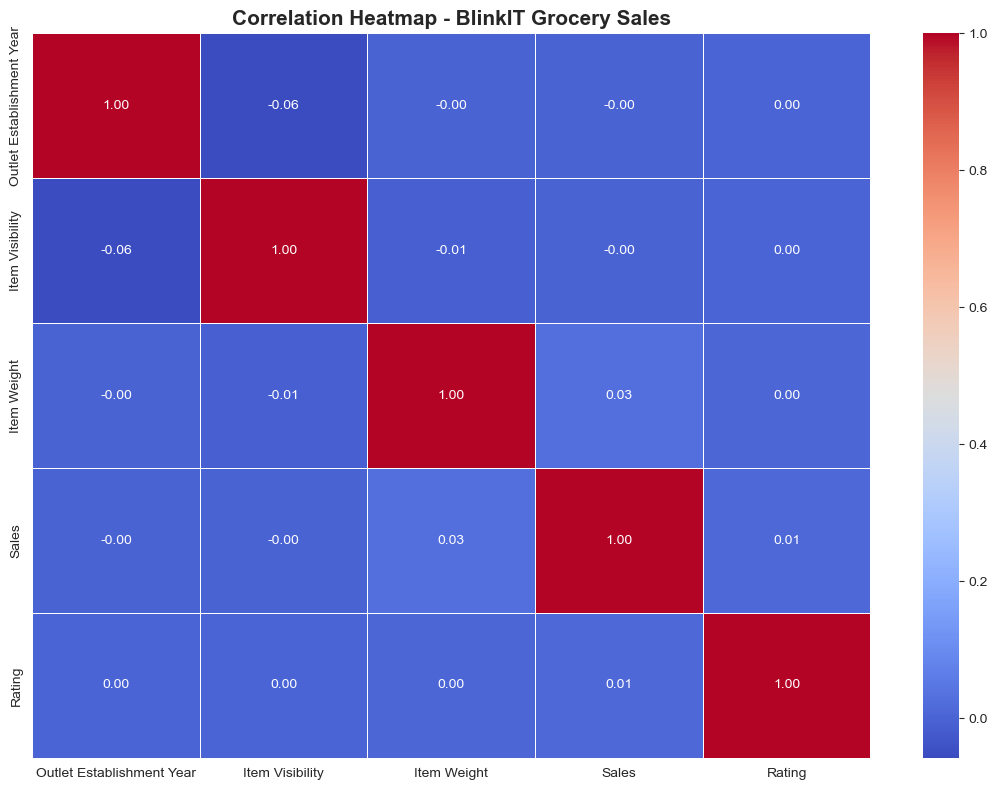

In [77]:
numerical_df = df.select_dtypes(include=np.number)

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title(
    'Correlation Heatmap - BlinkIT Grocery Sales',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [78]:
sales_correlation = (
    correlation_matrix['Sales']
    .drop('Sales')
    .sort_values(ascending=False)
)

print("CORRELATION WITH SALES")
print(sales_correlation.round(3))

CORRELATION WITH SALES
Item Weight                  0.026
Rating                       0.011
Outlet Establishment Year   -0.001
Item Visibility             -0.001
Name: Sales, dtype: float64


### Relationship and Correlation Insights

1. Item Visibility:
   The relationship between product visibility and sales
   is evaluated using scatter plots and correlation.

2. Item Weight:
   Product weight is analyzed to determine whether it
   has a meaningful relationship with sales.

3. Customer Rating:
   Customer ratings are compared with sales to understand
   whether customer feedback is associated with revenue.

4. Outlet Characteristics:
   Sales are compared across outlet sizes, locations,
   types and establishment years.

5. Correlation Analysis:
   The correlation heatmap provides an overview of
   relationships between numerical variables.

### Business Recommendations

1. Improve product placement where visibility analysis
   identifies potential opportunities.

2. Consider customer ratings alongside sales when
   reviewing product performance.

3. Evaluate outlet characteristics when planning
   operational improvements.

4. Avoid making business decisions based solely
   on correlation values.

## 4. High vs Low Performing Products and Outlets

This section compares product and outlet performance
to identify major revenue contributors and areas
requiring improvement.

In [79]:
product_performance = (
    df.groupby('Item Identifier')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Number_of_Outlets=('Outlet Identifier', 'nunique'),
        Average_Rating=('Rating', 'mean')
    )
    .sort_values('Total_Sales', ascending=False)
)

product_performance.head(10)

,Total_Sales,Average_Sales,Number_of_Outlets,Average_Rating
Item Identifier,,,,
FDU12,2371.0112,263.445689,9,4.144444
FDT07,2306.8970,256.321889,9,4.000000
NCQ06,2294.7126,254.968067,9,4.122222
FDL58,2111.6544,263.956800,8,3.862500
NCB31,2104.7280,263.091000,8,3.837500
FDX31,2104.4622,233.829133,9,4.055556
FDF05,2103.1280,262.891000,8,3.900000
FDR59,2096.5752,262.071900,8,3.787500
FDP28,2087.8488,260.981100,8,4.212500


In [80]:
top_10_products = product_performance.head(10)

print("TOP 10 PERFORMING PRODUCTS")
print(top_10_products.round(2))

TOP 10 PERFORMING PRODUCTS
                 Total_Sales  Average_Sales  Number_of_Outlets  Average_Rating
Item Identifier                                                               
FDU12                2371.01         263.45                  9            4.14
FDT07                2306.90         256.32                  9            4.00
NCQ06                2294.71         254.97                  9            4.12
FDL58                2111.65         263.96                  8            3.86
NCB31                2104.73         263.09                  8            3.84
FDX31                2104.46         233.83                  9            4.06
FDF05                2103.13         262.89                  8            3.90
FDR59                2096.58         262.07                  8            3.79
FDP28                2087.85         260.98                  8            4.21
FDA04                2072.07         259.01                  8            4.15


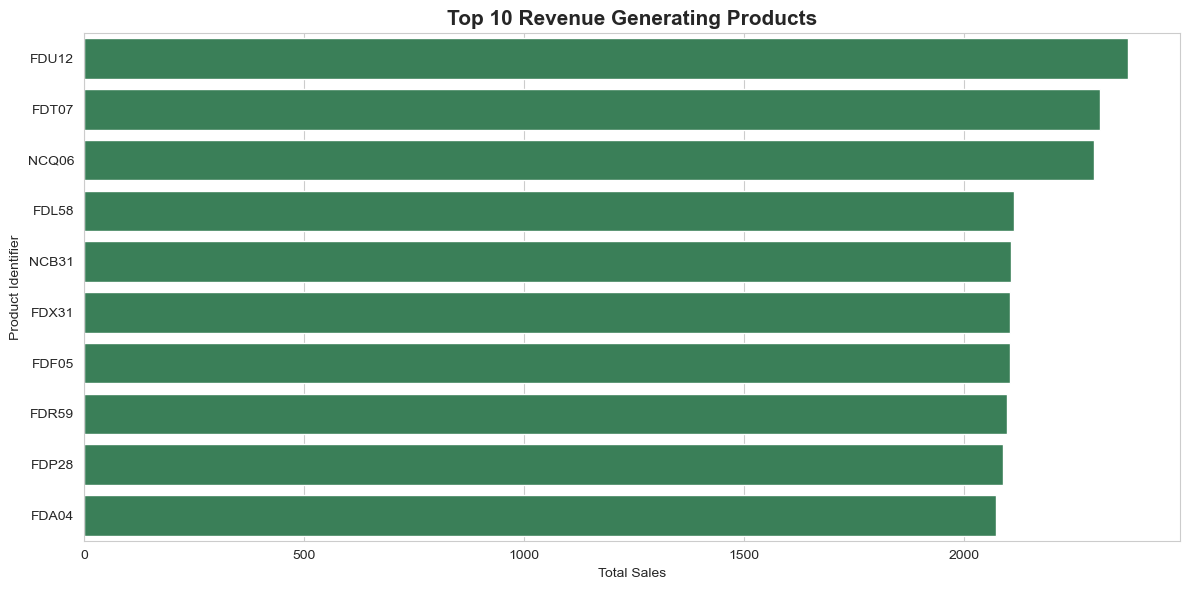

In [81]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_products['Total_Sales'].values,
    y=top_10_products.index,
    color='seagreen'
)

plt.title(
    'Top 10 Revenue Generating Products',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Total Sales')
plt.ylabel('Product Identifier')

plt.tight_layout()
plt.show()

In [82]:
bottom_10_products = (
    product_performance
    .sort_values('Total_Sales')
    .head(10)
)

print("BOTTOM 10 PERFORMING PRODUCTS")
print(bottom_10_products.round(2))

BOTTOM 10 PERFORMING PRODUCTS
                 Total_Sales  Average_Sales  Number_of_Outlets  Average_Rating
Item Identifier                                                               
NCC55                  72.87          36.43                  2            4.00
FDF38                  80.23          40.11                  2            4.00
FDN52                  86.92          86.92                  1            4.20
FDE52                  88.95          88.95                  1            4.00
NCR42                 101.07          33.69                  3            4.23
NCF55                 104.06          34.69                  3            4.10
FDM38                 107.90          53.95                  2            4.00
DRL59                 109.36          54.68                  2            3.70
FDU09                 109.49          54.75                  2            4.15
DRF51                 112.15          37.38                  3            4.07


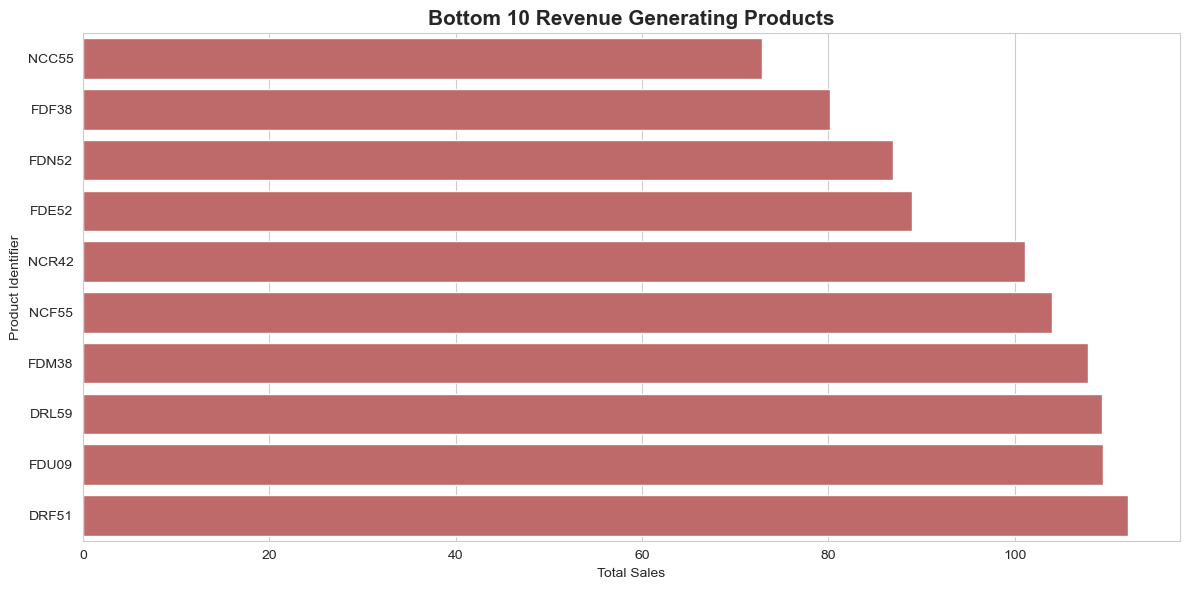

In [83]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=bottom_10_products['Total_Sales'].values,
    y=bottom_10_products.index,
    color='indianred'
)

plt.title(
    'Bottom 10 Revenue Generating Products',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Total Sales')
plt.ylabel('Product Identifier')

plt.tight_layout()
plt.show()

In [84]:
category_contribution = (
    df.groupby('Item Type')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Total_Records=('Sales', 'count')
    )
)

category_contribution['Sales_Percentage'] = (
    category_contribution['Total_Sales'] /
    total_sales * 100
)

category_contribution = category_contribution.sort_values(
    'Total_Sales',
    ascending=False
)

print(category_contribution.round(2))

                       Total_Sales  Average_Sales  Total_Records  \
Item Type                                                          
Fruits and Vegetables    178124.08         144.58           1232   
Snack Foods              175433.92         146.19           1200   
Household                135976.53         149.42            910   
Frozen Foods             118558.88         138.50            856   
Dairy                    101276.46         148.50            682   
Canned                    90706.73         139.76            649   
Baking Goods              81894.74         126.38            648   
Health and Hygiene        68025.84         130.82            520   
Meat                      59449.86         139.88            425   
Soft Drinks               58514.17         131.49            445   
Breads                    35379.12         140.95            251   
Hard Drinks               29334.68         137.08            214   
Others                    22451.89         132.8

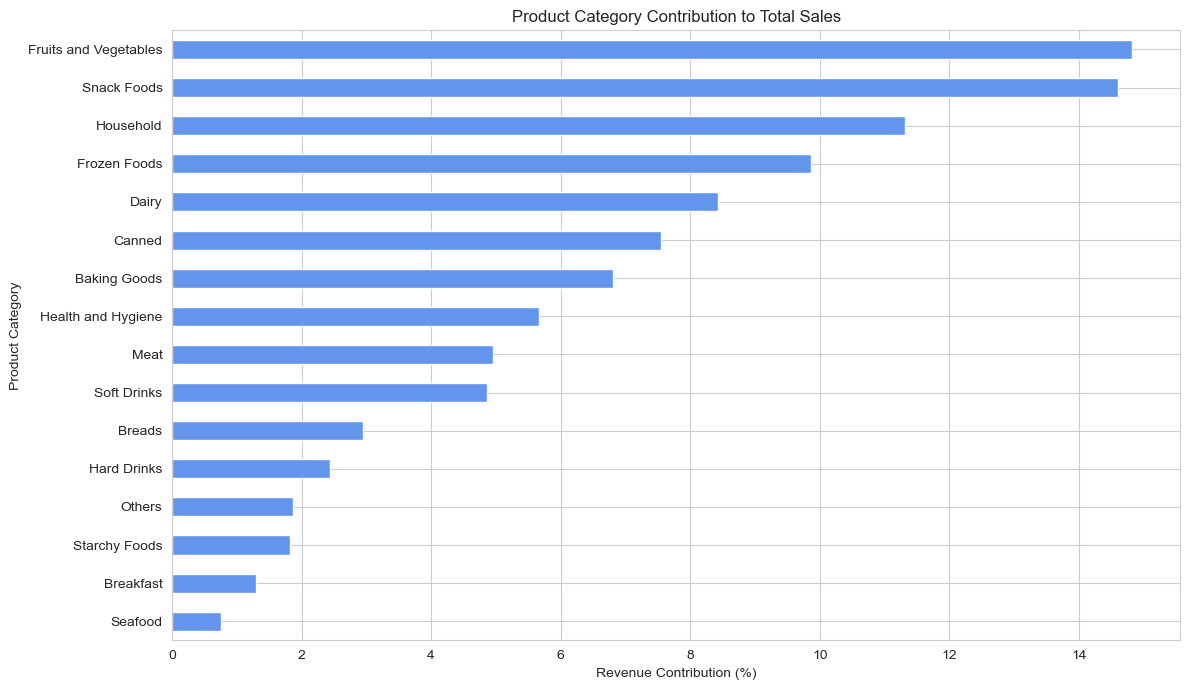

In [87]:
plt.figure(figsize=(12, 7))

category_contribution['Sales_Percentage'].sort_values().plot(
    kind='barh',
    color='cornflowerblue'
)

plt.title('Product Category Contribution to Total Sales')
plt.xlabel('Revenue Contribution (%)')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [88]:
outlet_performance = (
    df.groupby('Outlet Identifier')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Total_Records=('Sales', 'count'),
        Average_Rating=('Rating', 'mean')
    )
    .sort_values('Total_Sales', ascending=False)
)

print(outlet_performance.round(2))

                   Total_Sales  Average_Sales  Total_Records  Average_Rating
Outlet Identifier                                                           
OUT035               133103.91         143.12            930            3.94
OUT046               132113.37         142.06            930            3.96
OUT013               131809.02         141.43            932            3.95
OUT018               131477.78         141.68            928            3.97
OUT045               130942.78         140.95            929            3.96
OUT027               130714.67         139.80            935            3.95
OUT049               130476.86         140.30            930            3.99
OUT017               129103.96         139.42            926            3.98
OUT010                78131.57         140.78            555            3.98
OUT019                73807.58         139.79            528            4.00


In [89]:
print("TOP 5 OUTLETS")

print(outlet_performance.head(5).round(2))

print("\nBOTTOM 5 OUTLETS")

print(outlet_performance.tail(5).round(2))

TOP 5 OUTLETS
                   Total_Sales  Average_Sales  Total_Records  Average_Rating
Outlet Identifier                                                           
OUT035               133103.91         143.12            930            3.94
OUT046               132113.37         142.06            930            3.96
OUT013               131809.02         141.43            932            3.95
OUT018               131477.78         141.68            928            3.97
OUT045               130942.78         140.95            929            3.96

BOTTOM 5 OUTLETS
                   Total_Sales  Average_Sales  Total_Records  Average_Rating
Outlet Identifier                                                           
OUT027               130714.67         139.80            935            3.95
OUT049               130476.86         140.30            930            3.99
OUT017               129103.96         139.42            926            3.98
OUT010                78131.57         140.7

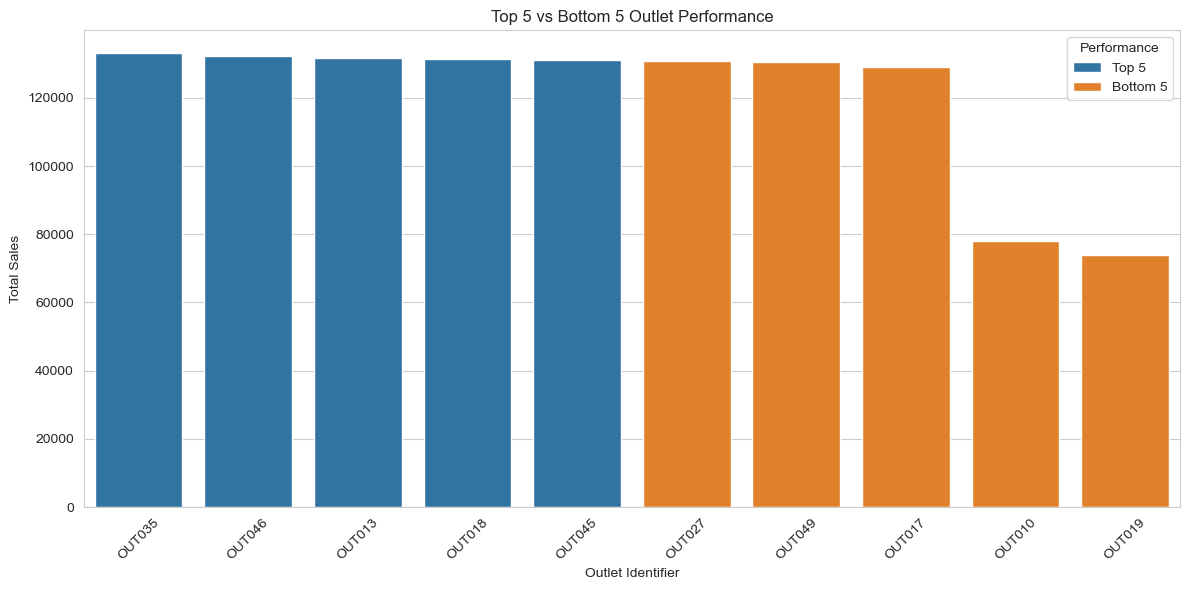

In [90]:
comparison = pd.concat([
    outlet_performance.head(5).assign(
        Performance='Top 5'
    ),
    outlet_performance.tail(5).assign(
        Performance='Bottom 5'
    )
])

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison,
    x=comparison.index,
    y='Total_Sales',
    hue='Performance'
)

plt.title('Top 5 vs Bottom 5 Outlet Performance')
plt.xlabel('Outlet Identifier')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### High vs Low Performing Products and Outlets

1. The top-performing products contribute significantly
   to overall BlinkIT revenue.

2. The lowest-performing products require further
   investigation based on their availability and sales.

3. Product category contribution analysis identifies
   the categories responsible for major revenue generation.

4. Outlet-level comparison highlights differences
   in revenue contribution across locations.

5. Comparing average sales and total sales provides
   a more balanced understanding of outlet performance.

### Management Recommendations

1. Ensure sufficient inventory of high-revenue products.

2. Investigate the reasons behind low product sales
   before making assortment decisions.

3. Study the operating strategies of top-performing outlets.

4. Review low-performing outlets to identify possible
   operational and inventory-related issues.

5. Allocate marketing and promotional resources
   based on category-level performance.

## 5. Actionable Business Insights and Recommendations

### 1. Product Category Optimization

Fruits and Vegetables and Snack Foods are the
largest revenue-generating categories.

Recommendation:
- Maintain sufficient inventory of these categories.
- Monitor product availability and demand.
- Develop category-specific promotional campaigns.

### 2. Outlet Performance Improvement

Supermarket Type1 contributes approximately 65.54%
of total sales.

Recommendation:
- Study the operational strategies of these outlets.
- Identify practices that can be adopted by other outlets.
- Monitor outlet-level sales performance.

### 3. Location-Based Strategy

Tier 3 locations contribute the highest total sales.

Recommendation:
- Investigate customer demand in Tier 3 locations.
- Evaluate opportunities for improving inventory.
- Consider location-specific expansion opportunities
  after studying operating costs and profitability.

### 4. Product Performance Optimization

Some products contribute significantly more revenue
than others.

Recommendation:
- Monitor high-revenue products.
- Review low-revenue products before discontinuation.
- Evaluate availability and customer demand.

### 5. Customer Satisfaction

The average customer rating is 3.97 out of 5.

Recommendation:
- Continue monitoring customer feedback.
- Investigate products receiving lower ratings.
- Improve product quality and customer experience.

### 6. Data-Driven Decision Making

The correlation analysis shows weak linear relationships
between individual numerical variables and sales.

Recommendation:
- Evaluate multiple business factors together.
- Avoid making decisions using correlation alone.
- Conduct further analysis using transaction-level
  and operational data.

## 6. Conclusion

The BlinkIT Grocery Sales Analysis project focused on
understanding product performance, outlet performance,
customer ratings, and overall sales distribution.

Using Python, Pandas, NumPy, Matplotlib, and Seaborn,
the dataset was inspected, cleaned, and analyzed.

The analysis revealed that Fruits and Vegetables
and Snack Foods are the leading revenue-generating
product categories.

Supermarket Type1 outlets contribute the largest
share of total sales, while Tier 3 locations generate
the highest sales among location categories.

The average customer rating is 3.97, indicating
generally positive customer feedback.

Correlation analysis showed that individual numerical
variables such as item weight, visibility, and ratings
have very weak linear relationships with sales.

Overall, this project demonstrates how data analysis
can help management understand sales patterns,
evaluate product and outlet performance, and make
more informed business decisions.